# Task 3, Step 1: Rollout Data and the Opportunity from Repeated Sampling

**Manual step 1.** Load and join the supplied tables, verify token-list alignment, form answer groups and correctness labels, then measure what repeated sampling could offer before any selection rule is applied.

- **FirstAns accuracy:** what one sample achieves.
- **Oracle coverage:** whether *any* candidate is correct. This uses gold answers, so it is an analysis upper bound, not a method.
- **Distinct answer groups:** whether extra samples add alternatives or repeat existing answers.
- **Failure decomposition:** a question can fail because no correct candidate was generated (a sampling limit) or because one was generated and missed (a selection limit).

Every number below is computed from the supplied parquet files.

In [1]:
import os, sys, json
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "task3_test_time_compute")):
    root = os.path.dirname(root)
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from task3_test_time_compute.src.notebook_utils import *
setup_notebook()

In [2]:
from task3_test_time_compute.src.data import FOLDERS, load_and_join_rollouts, verify_alignment
from task3_test_time_compute.src.evaluate import make_orders, run_coverage_analysis, run_offline_budget_evaluation, decompose_failures
from task3_test_time_compute.src.normalization import scorer_version, NO_ANSWER

print("Scorer:", scorer_version())
checks = {}
tables = {}
for dataset in DATASETS:
    is_vlm = dataset == "mathvista"
    tables[dataset] = load_and_join_rollouts(os.path.join(DATA_DIR, FOLDERS[dataset]), is_vlm=is_vlm)
    checks[DATASETS[dataset]] = verify_alignment(tables[dataset], is_vlm=is_vlm)
alignment = pd.DataFrame(checks).T
alignment.to_csv(f"{RESULTS_DIR}/data_alignment.csv")
display(alignment)

Scorer: math-verify 0.9.0


,rollouts,questions,retained_tokens,capped,null_extractions
MATH (Qwen2.5-3B),32000,1000,20742094,523,521
MathVista (Qwen2.5-VL-3B),32000,1000,8961703,487,3032


## 1.1 What the rollouts look like
Compare retained token counts with the supplied README's export totals above. Capped responses and failed extractions stay in the experiment: removing them would inflate scores.

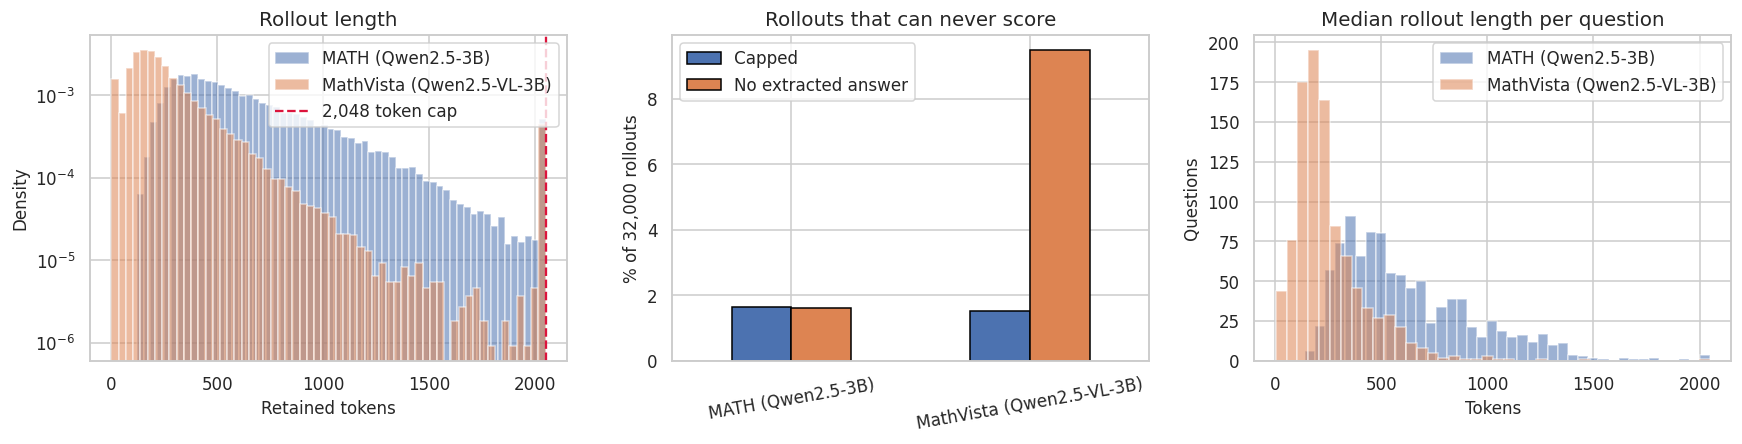

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for dataset, label in DATASETS.items():
    df = tables[dataset]
    lengths = df["n_generated_text_tokens"].clip(upper=2048)
    axes[0].hist(lengths, bins=60, alpha=0.55, label=label, density=True)
axes[0].axvline(2048, color="crimson", linestyle="--", label="2,048 token cap")
axes[0].set(title="Rollout length", xlabel="Retained tokens", ylabel="Density", yscale="log")
axes[0].legend()

rates = pd.DataFrame({DATASETS[d]: {"Capped": tables[d]["hit_max_new_tokens"].mean() * 100, "No extracted answer": tables[d]["extracted_answer"].isna().mean() * 100} for d in DATASETS}).T
rates.plot(kind="bar", ax=axes[1], rot=10, edgecolor="black")
axes[1].set(title="Rollouts that can never score", ylabel="% of 32,000 rollouts")

for dataset, label in DATASETS.items():
    per_q = tables[dataset].groupby("sample_id")["n_generated_text_tokens"].median()
    axes[2].hist(per_q, bins=40, alpha=0.55, label=label)
axes[2].set(title="Median rollout length per question", xlabel="Tokens", ylabel="Questions")
axes[2].legend()
save_figure("task3_1_rollout_overview")

## 1.2 Normalize, group, and split
Answers are grouped **without gold answers** using math-verify (MATH) and MathVista's type, choice, and precision rules. Missing extractions become one `NO_ANSWER` group, graded incorrect. Splits sort IDs, then permute with `default_rng(6304)`: 200 development, 800 held-out, and the first 50 held-out MATH questions for the live experiment.

In [4]:
del tables
questions = {}
rows = []
for dataset, label in DATASETS.items():
    dev, test, splits = split_questions(dataset)
    questions[dataset] = {"dev": dev, "test": test}
    all_q = dev + test
    rows.append({"Dataset": label, "Development": len(dev), "Held-out": len(test), "Live subset": len(splits["live"]) if dataset == "math" else 0,
                 "Mean answer groups (N=32)": np.mean([len(set(q.groups)) for q in all_q]),
                 "Mean correct rollouts of 32": np.mean([q.correct.sum() for q in all_q]),
                 "Gold answer in some rollout (%)": 100 * np.mean([q.correct.any() for q in all_q])})
display(pd.DataFrame(rows).round(2))

Timeout during comparison


Timeout during comparison


Timeout during comparison


Timeout during comparison


Timeout during comparison


Timeout during comparison


... (31 outputs left out)

Timeout during comparison


Timeout during comparison


Timeout during comparison


,Dataset,Development,Held-out,Live subset,Mean answer groups (N=32),Mean correct rollouts of 32,Gold answer in some rollout (%)
0,MATH (Qwen2.5-3B),200,800,50,5.65,21.22,91.9
1,MathVista (Qwen2.5-VL-3B),200,800,0,5.02,17.18,89.4


## 1.3 Oracle coverage and the selection gap
Reported on the held-out questions. The gap between the oracle curve and FirstAns is the most any selection rule could recover at that budget.

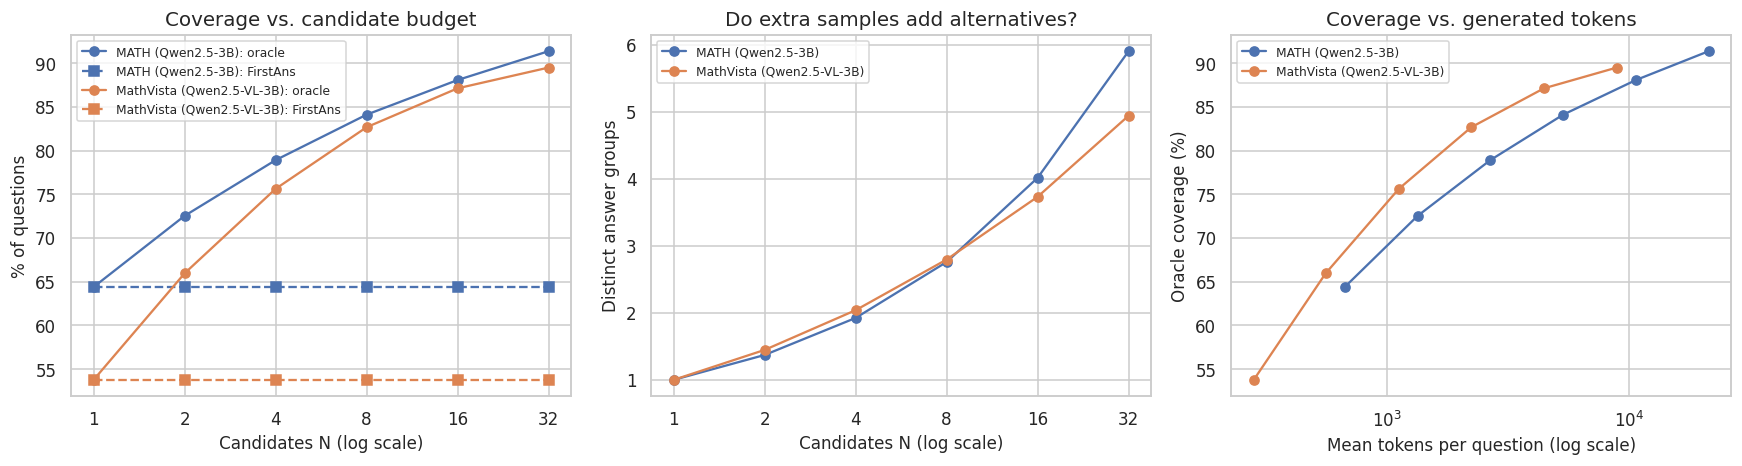

In [5]:
coverage = {}
for dataset in DATASETS:
    test = questions[dataset]["test"]
    coverage[dataset] = run_coverage_analysis(test, make_orders(test))
    coverage[dataset].assign(dataset=dataset).to_csv(f"{RESULTS_DIR}/coverage_{dataset}.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for dataset, label in DATASETS.items():
    summary = coverage[dataset].groupby("N")[["first_ans", "oracle_coverage", "distinct_groups", "token_cost"]].mean()
    line = axes[0].plot(summary.index, summary["oracle_coverage"] * 100, marker="o", label=f"{label}: oracle")[0]
    axes[0].plot(summary.index, summary["first_ans"] * 100, marker="s", linestyle="--", color=line.get_color(), label=f"{label}: FirstAns")
    axes[1].plot(summary.index, summary["distinct_groups"], marker="o", label=label)
    axes[2].plot(summary["token_cost"], summary["oracle_coverage"] * 100, marker="o", label=label)
axes[0].set(title="Coverage vs. candidate budget", xlabel="Candidates N (log scale)", ylabel="% of questions", xscale="log")
axes[1].set(title="Do extra samples add alternatives?", xlabel="Candidates N (log scale)", ylabel="Distinct answer groups", xscale="log")
axes[2].set(title="Coverage vs. generated tokens", xlabel="Mean tokens per question (log scale)", ylabel="Oracle coverage (%)", xscale="log")
for ax in axes[:2]:
    ax.set_xticks([1, 2, 4, 8, 16, 32])
    ax.set_xticklabels([1, 2, 4, 8, 16, 32])
for ax in axes:
    ax.legend(fontsize=8)
save_figure("task3_1_oracle_coverage")

## 1.4 Sampling failures versus selection failures
Self-consistency is the reference selector here. **Red** cannot be fixed by a better selector at that budget. **Orange** could be.

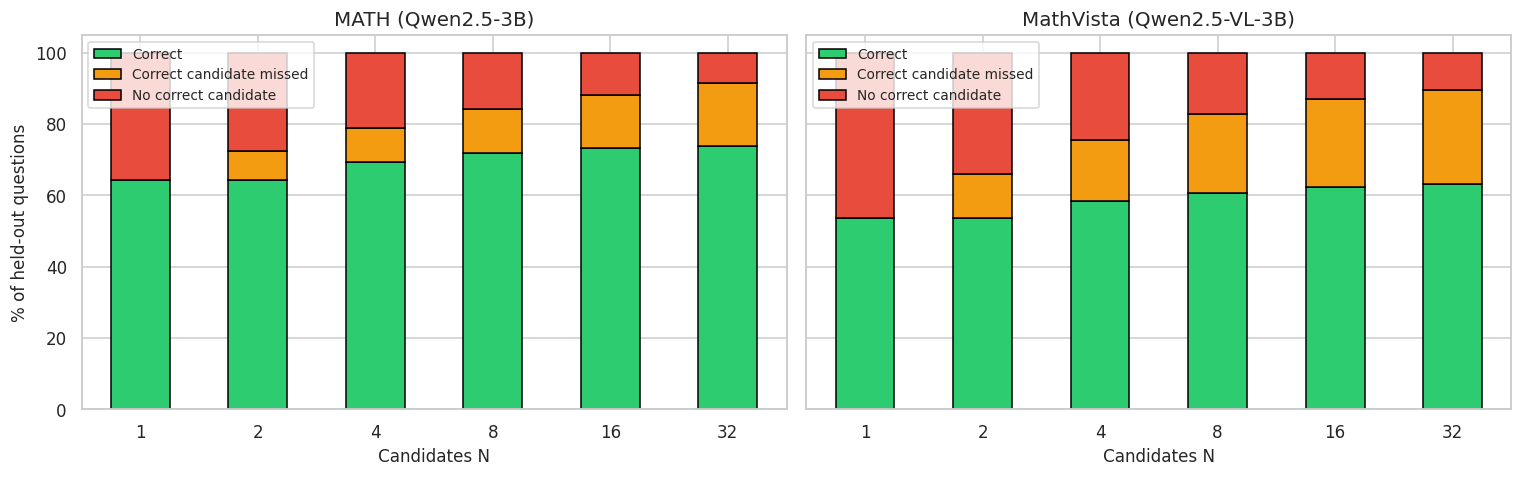

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (dataset, label) in zip(axes, DATASETS.items()):
    test = questions[dataset]["test"]
    results = run_offline_budget_evaluation(test, make_orders(test), methods=["self_consistency"])
    decomposition = decompose_failures(results, coverage[dataset]).set_index("N") * 100
    decomposition.to_csv(f"{RESULTS_DIR}/failure_decomposition_{dataset}.csv")
    decomposition[["correct", "missed_available", "no_correct_candidate"]].plot(kind="bar", stacked=True, ax=ax, color=["#2ecc71", "#f39c12", "#e74c3c"], edgecolor="black", rot=0)
    ax.set(title=label, xlabel="Candidates N", ylabel="% of held-out questions")
    ax.legend(["Correct", "Correct candidate missed", "No correct candidate"], fontsize=9)
save_figure("task3_1_failure_decomposition")

## 1.5 How often do rollouts agree?
Each point on this distribution is one question: the share of its 32 rollouts that are correct. Questions near 0 or 1 give selection little to do; the middle is where selection decides the outcome.

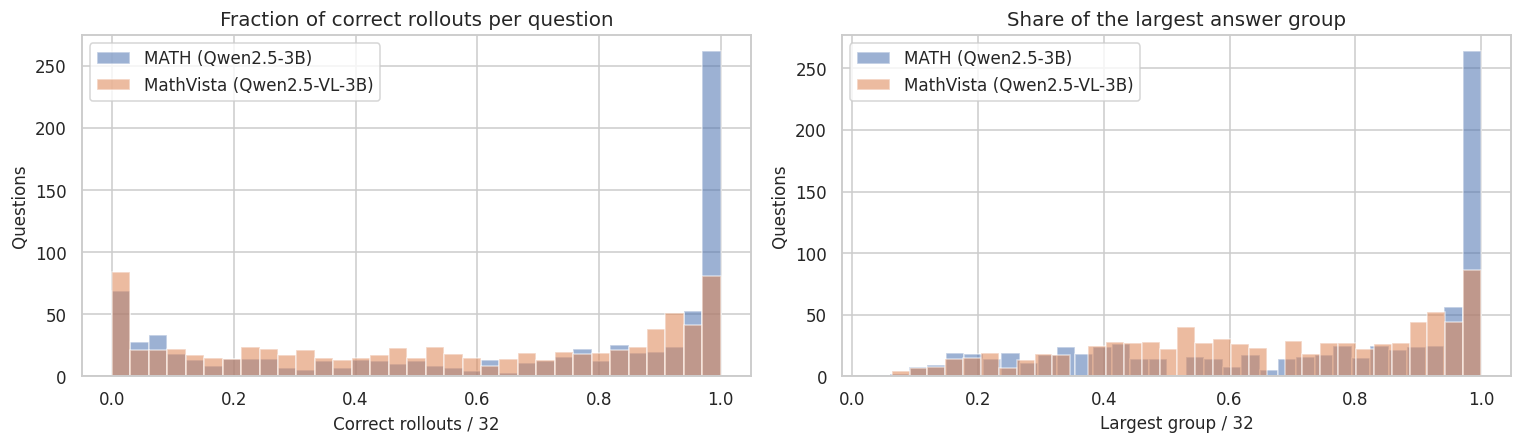

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for dataset, label in DATASETS.items():
    all_q = questions[dataset]["test"]
    axes[0].hist([q.correct.mean() for q in all_q], bins=33, alpha=0.55, label=label)
    axes[1].hist([np.bincount(q.groups).max() / 32 for q in all_q], bins=33, alpha=0.55, label=label)
axes[0].set(title="Fraction of correct rollouts per question", xlabel="Correct rollouts / 32", ylabel="Questions")
axes[1].set(title="Share of the largest answer group", xlabel="Largest group / 32", ylabel="Questions")
axes[0].legend(); axes[1].legend()
save_figure("task3_1_agreement_distribution")